In [8]:
from tbparse import SummaryReader
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
import glob 
import scienceplots

print("Current working directory:", pathlib.Path.cwd().parent.parent)

source_dir = pathlib.Path.cwd().parent.parent
print("Source directory:", source_dir)
# make a list of all events in the log file
from pathlib import Path
source_dir = str(source_dir)

source_dir = source_dir + "/logs/skrl/"
print("Source directory with logs:", source_dir)

sns.set_style("whitegrid")  # Choose your style
sns.set_context("paper")
plt.style.use(['science', 'ieee'])
# sns.set_style("whitegrid")  # Choose your style
# sns.set_context("paper")    

# collect all dirs
paths = sorted(glob.glob(source_dir + "/*/events*"))
print(paths)

Current working directory: /home/vikas-admin/Codebases/SPEAR/QuadControl
Source directory: /home/vikas-admin/Codebases/SPEAR/QuadControl
Source directory with logs: /home/vikas-admin/Codebases/SPEAR/QuadControl/logs/skrl/
[]


With tensorboard dataframes

In [9]:
import glob

log_dir = f"../logs/skrl/baseline/*/events.out.*"
paths = sorted(glob.glob(source_dir))
paths

['/home/vikas-admin/Codebases/SPEAR/QuadControl/logs/skrl/']

In [10]:
tasks = ["line", "circle", "lemniscate", "slalom"]

In [11]:
from tensorboard.backend.event_processing import event_accumulator
import pandas as pd
import os

def extract_scalars(log_dir, algorithm, task, run_id):
    ea = event_accumulator.EventAccumulator(log_dir)
    ea.Reload()
    data = []
    for tag in ea.Tags()["scalars"]:
        for s in ea.Scalars(tag):
            data.append({
                "step": s.step,
                "value": s.value,
                "tag": tag,
                "algorithm": algorithm,
                "task": task,
                "run": run_id
            })
    return pd.DataFrame(data)

# Aggregate all logs
base_dir = source_dir
all_dfs = []
for algorithm in ["baseline", "pretrained-init"]:
    for task in tasks:
        task_dir = os.path.join(base_dir, algorithm, task)
        for run in os.listdir(task_dir):
            log_path = os.path.join(task_dir, run)
            df = extract_scalars(log_path, algorithm, task, run)
            all_dfs.append(df)

full_df = pd.concat(all_dfs)


In [12]:
full_df.head()

,step,value,tag,algorithm,task,run
0,48,0.118525,Reward / Instantaneous reward (max),baseline,line,events.out.tfevents.1755158917.rat-nb-162.2018...
1,96,0.124365,Reward / Instantaneous reward (max),baseline,line,events.out.tfevents.1755158917.rat-nb-162.2018...
2,144,0.134856,Reward / Instantaneous reward (max),baseline,line,events.out.tfevents.1755158917.rat-nb-162.2018...
3,192,0.125705,Reward / Instantaneous reward (max),baseline,line,events.out.tfevents.1755158917.rat-nb-162.2018...
4,240,0.132170,Reward / Instantaneous reward (max),baseline,line,events.out.tfevents.1755158917.rat-nb-162.2018...


In [13]:
full_df['tag'].unique()

array(['Reward / Instantaneous reward (max)',
       'Reward / Instantaneous reward (min)',
       'Reward / Instantaneous reward (mean)',
       'Reward / Total reward (max)', 'Reward / Total reward (min)',
       'Reward / Total reward (mean)', 'Episode / Total timesteps (max)',
       'Episode / Total timesteps (min)',
       'Episode / Total timesteps (mean)',
       'Info / Episode_Reward/lin_vel', 'Info / Episode_Reward/ang_vel',
       'Info / Episode_Reward/distance_to_goal', 'Loss / Policy loss',
       'Loss / Value loss', 'Policy / Standard deviation',
       'Learning / Learning rate', 'Info / Episode_Reward/bonus'],
      dtype=object)

Text(0.5, 1.0, 'Aggregate Reward Comparison Across Tasks')

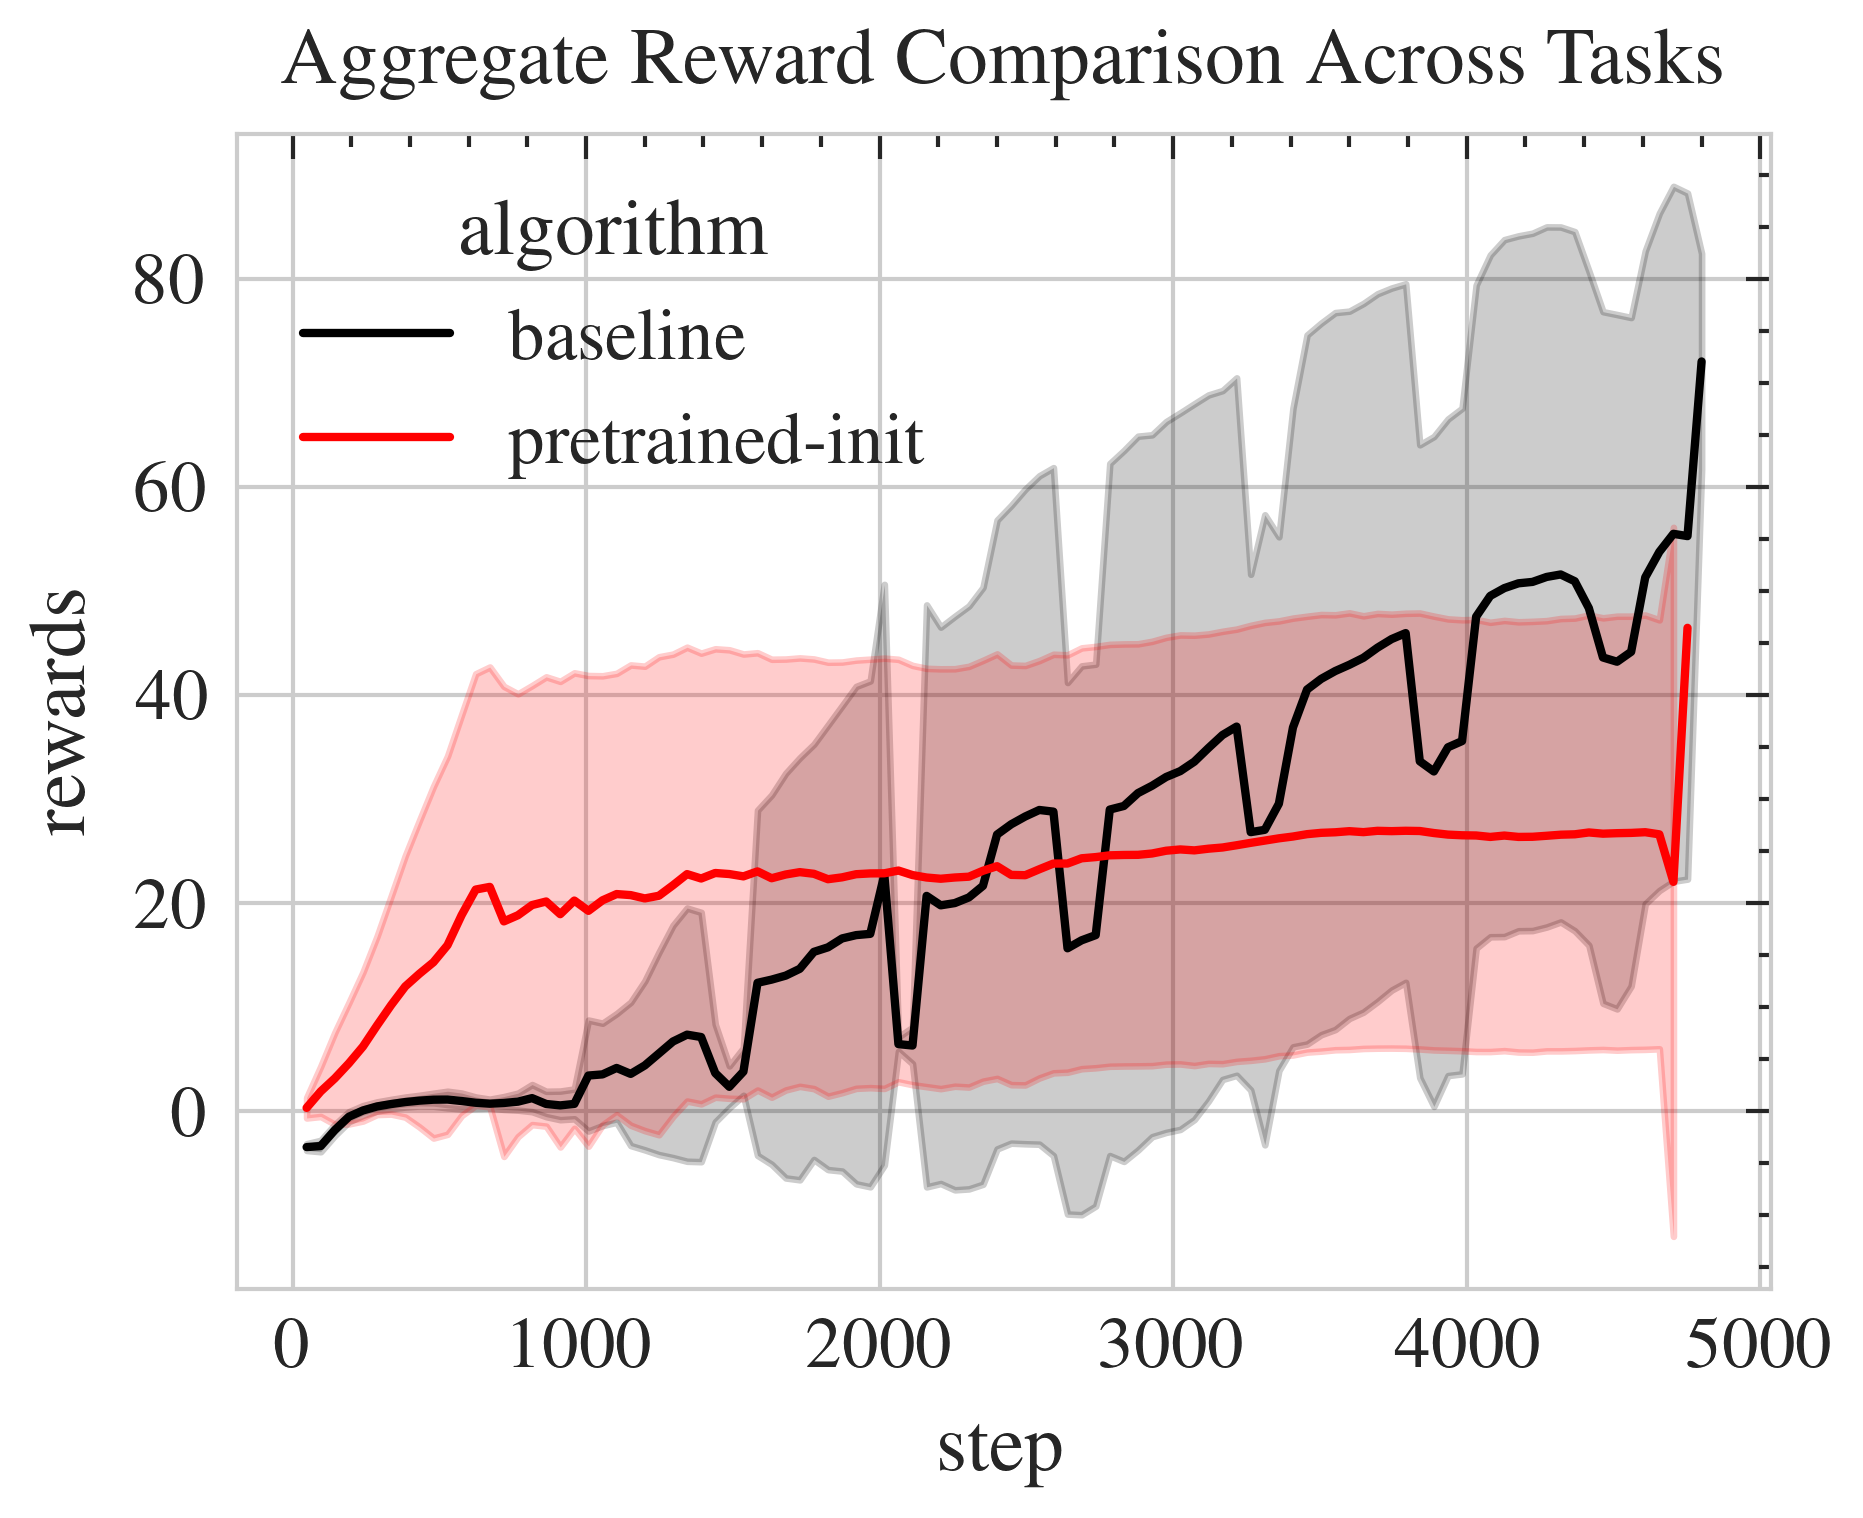

In [14]:
summary = (
    full_df.query("tag == 'Reward / Total reward (mean)'")
    .groupby(["algorithm", "task", "step"])
    .agg(rewards=("value", "mean"), std_loss=("value", "std"))
    .reset_index()
)
# plt.figure(figsize=(3,3))
ax = sns.lineplot(
    data=summary,
    x="step", y="rewards",
    hue="algorithm",
    # style="task",
    errorbar="sd",
    # size=(10,10)
)

plt.title("Aggregate Reward Comparison Across Tasks")
# plt.savefig("aggregate_reward_comparison.pdf", dpi=300)

# plt.savefig("aggregate_reward_comparison.png", dpi=300)

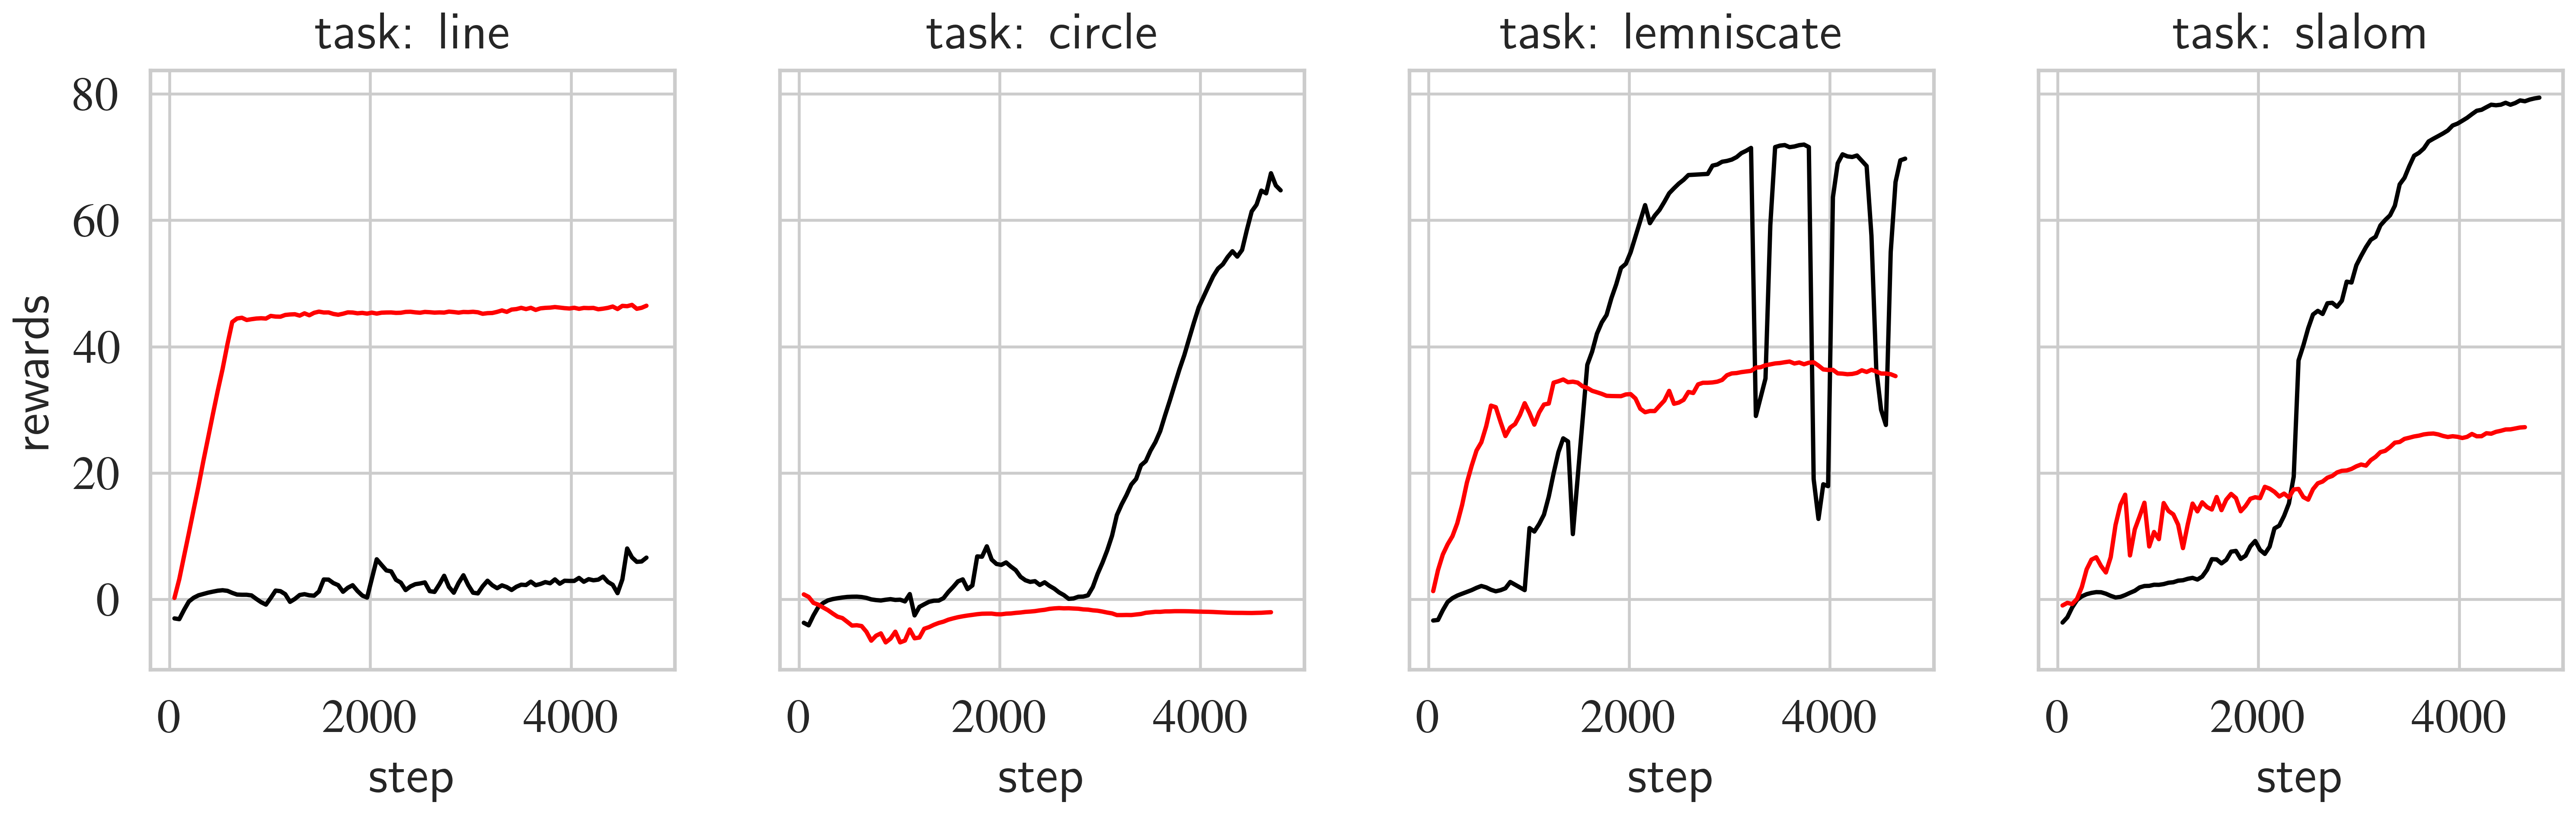

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_context("paper", font_scale=1.5)
plt.rcParams.update({'font.size': 11})
fig, axes = plt.subplots(1, len(tasks), figsize=(12, 3), sharey=True, sharex=True)
# axes = axes.flatten()
# fig.fontsize = 50
for i, t in enumerate(tasks):
    # plt.figure(figsize=(5, 4))
    axes[i] = sns.lineplot(
        data=summary[summary["task"] == t],
        x="step", y="rewards",
        hue="algorithm",
        # errorbar="sd",
        ax=axes[i]
    )
    # plt.title(f"Reward Comparison for {t} Task")
    # plt.xlabel("Step")
    # plt.ylabel("Average Reward")
    axes[i].set_title(f"task: {t}")
    axes[i].legend_.remove()
    # plt.savefig(f"reward_comparison_{t}.pdf", dpi=300)
    # plt.show()




handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, loc='best', ncols=1, title="Training type")
# plt.title("Aggregate Reward Comparison Across Tasks")
# plt.savefig("task_reward_comparison_horizontal.pdf", dpi=300,)

plt.savefig("aggregate_reward_comparison_sep.png", dpi=300)


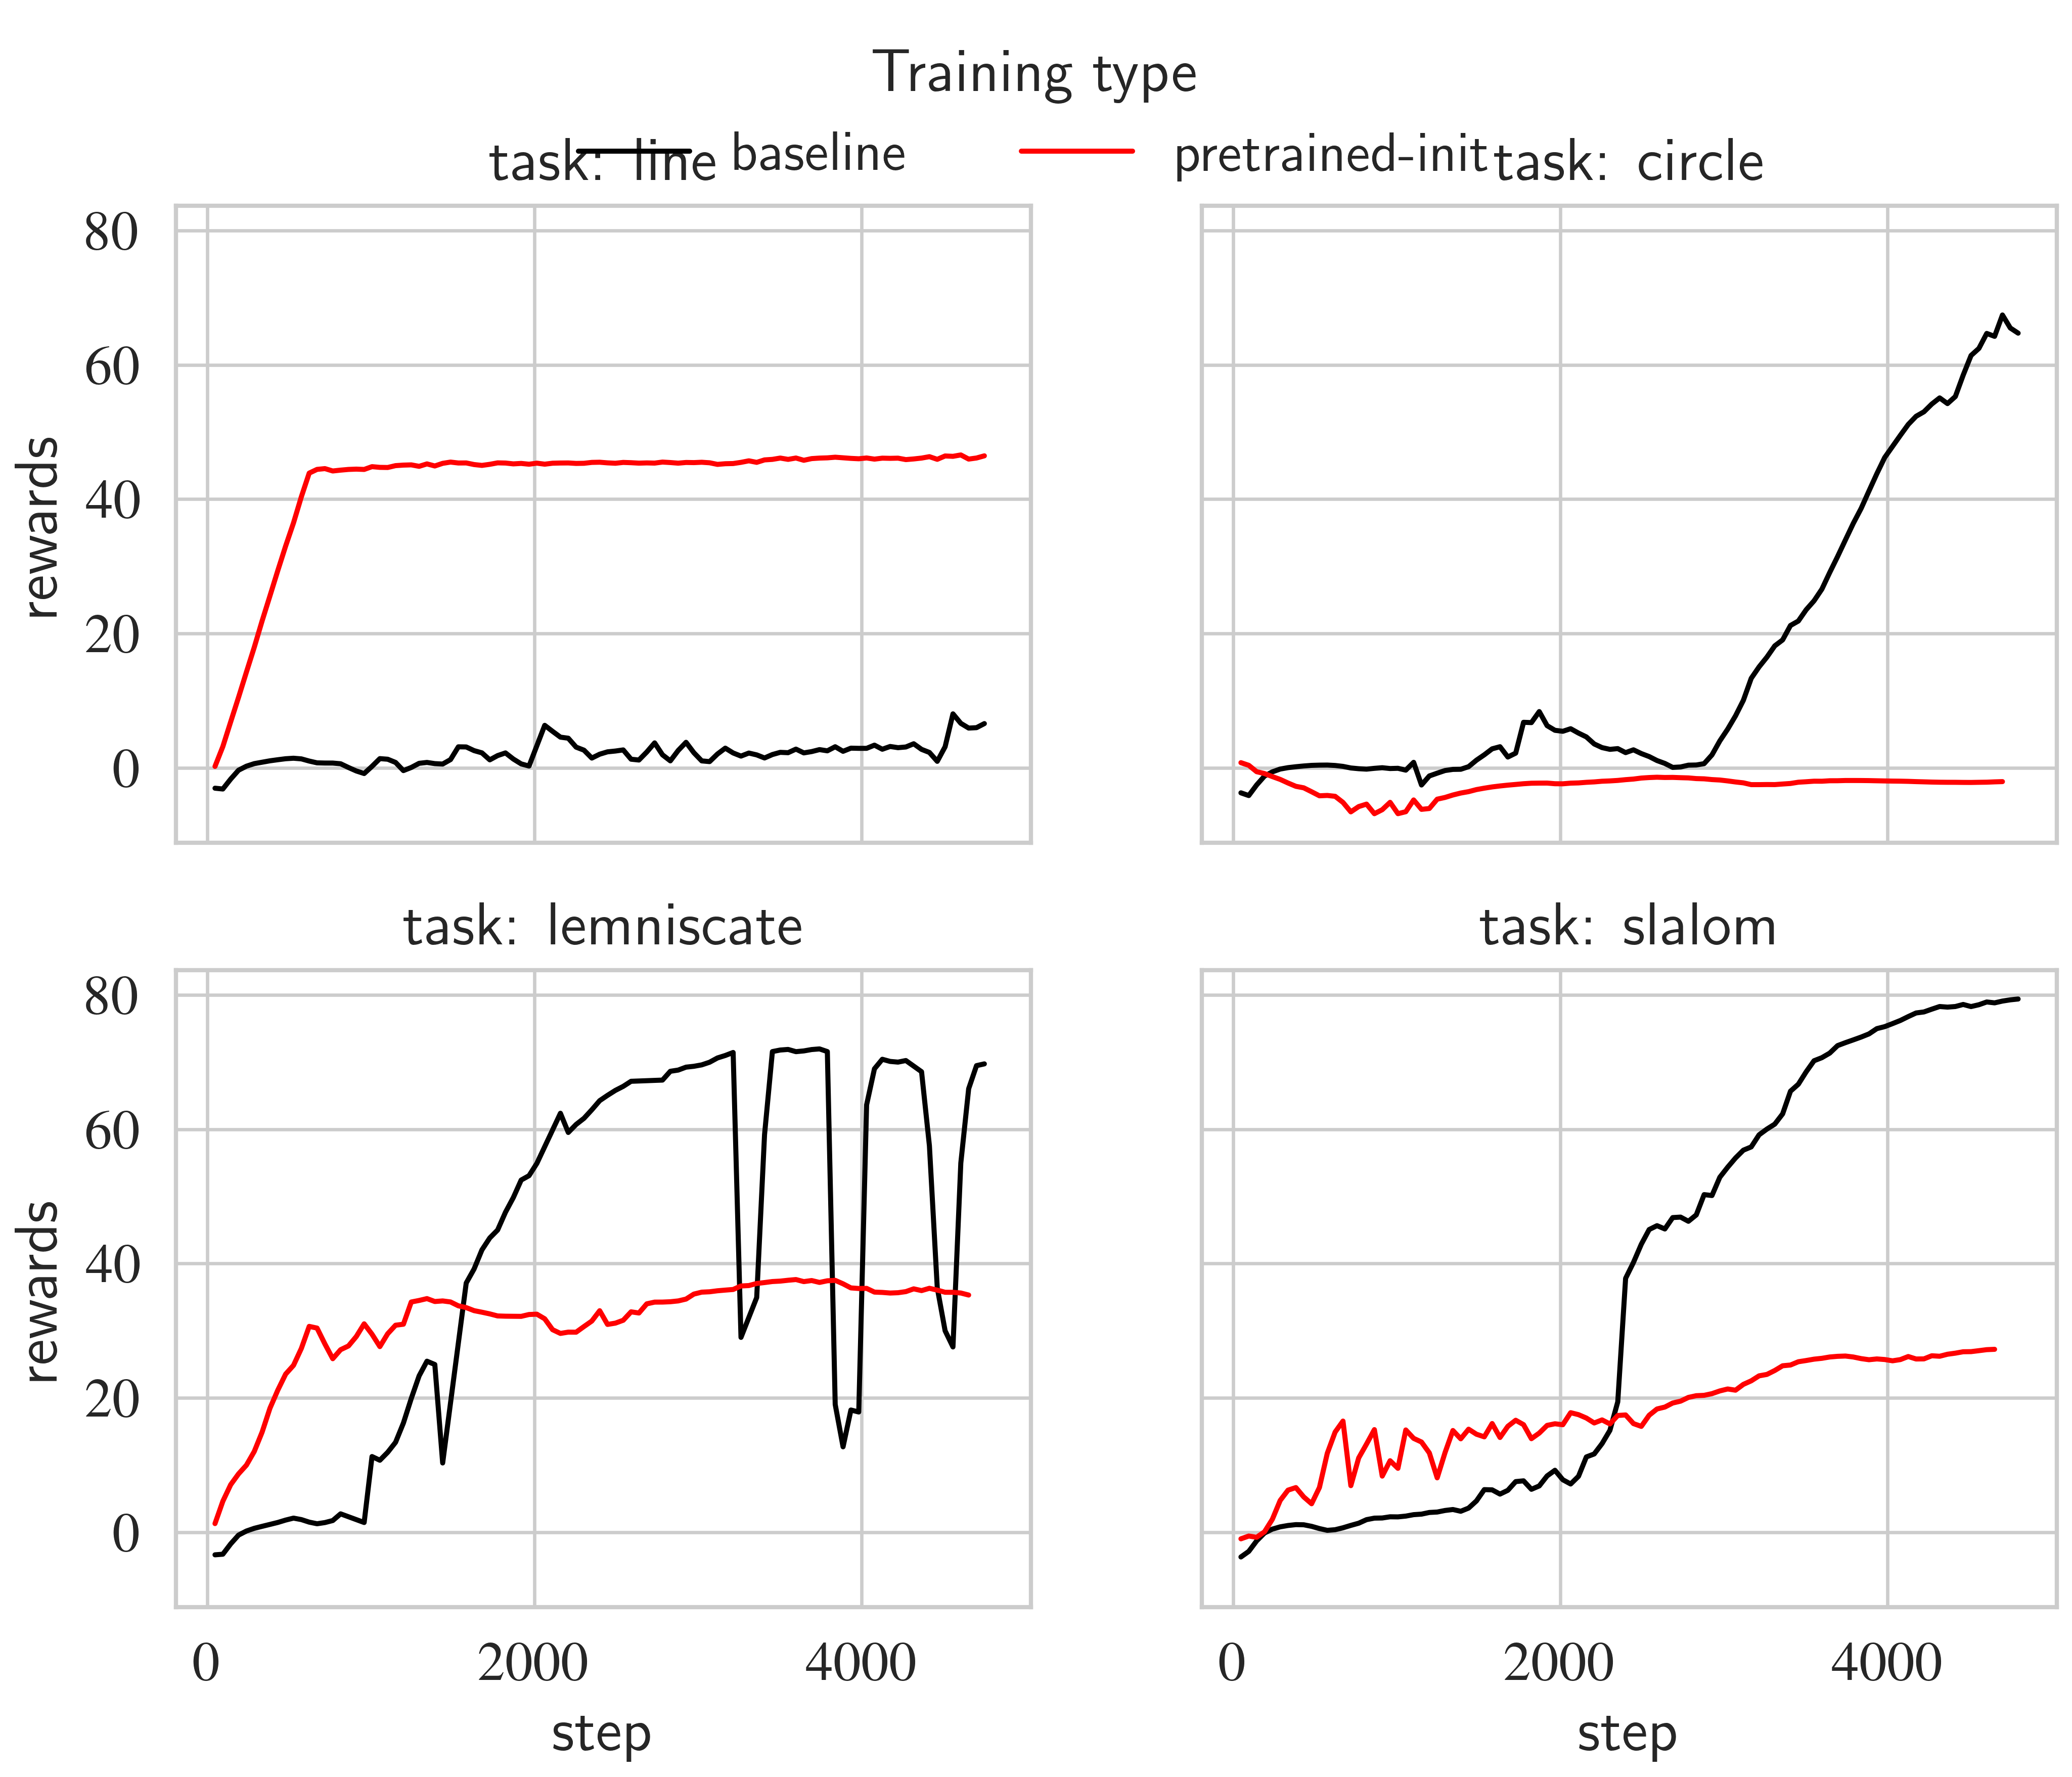

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, len(tasks)//2, figsize=(4 * 2, 3 * 2), sharey=True, sharex=True)
axes = axes.flatten()

for i, t in enumerate(tasks):
    # plt.figure(figsize=(5, 4))
    axes[i] = sns.lineplot(
        data=summary[summary["task"] == t],
        x="step", y="rewards",
        hue="algorithm",
        # errorbar="sd",
        ax=axes[i]
    )
    # plt.title(f"Reward Comparison for {t} Task")
    # plt.xlabel("Step")
    # plt.ylabel("Average Reward")
    axes[i].set_title(f"task: {t}")
    axes[i].legend_.remove()
    # plt.savefig(f"reward_comparison_{t}.pdf", dpi=300)
    # plt.show()




handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, title="Training type")
# plt.title("Aggregate Reward Comparison Across Tasks")
plt.savefig("task_reward_comparison.png", dpi=300)


In [ ]:
loss_summary = (
    full_df.query("tag == ['Loss / Policy loss']")
    .groupby(["algorithm", "task", "step", "tag"])
    .agg(losses=("value", "mean"), std_loss=("value", "std"))
    .reset_index()
)

summary_2 = (
    full_df.query("tag == ['Loss / Value loss']")
    .groupby(["algorithm", "task", "step", "tag"])
    .agg(losses=("value", "mean"), std_loss=("value", "std"))
    .reset_index()
)



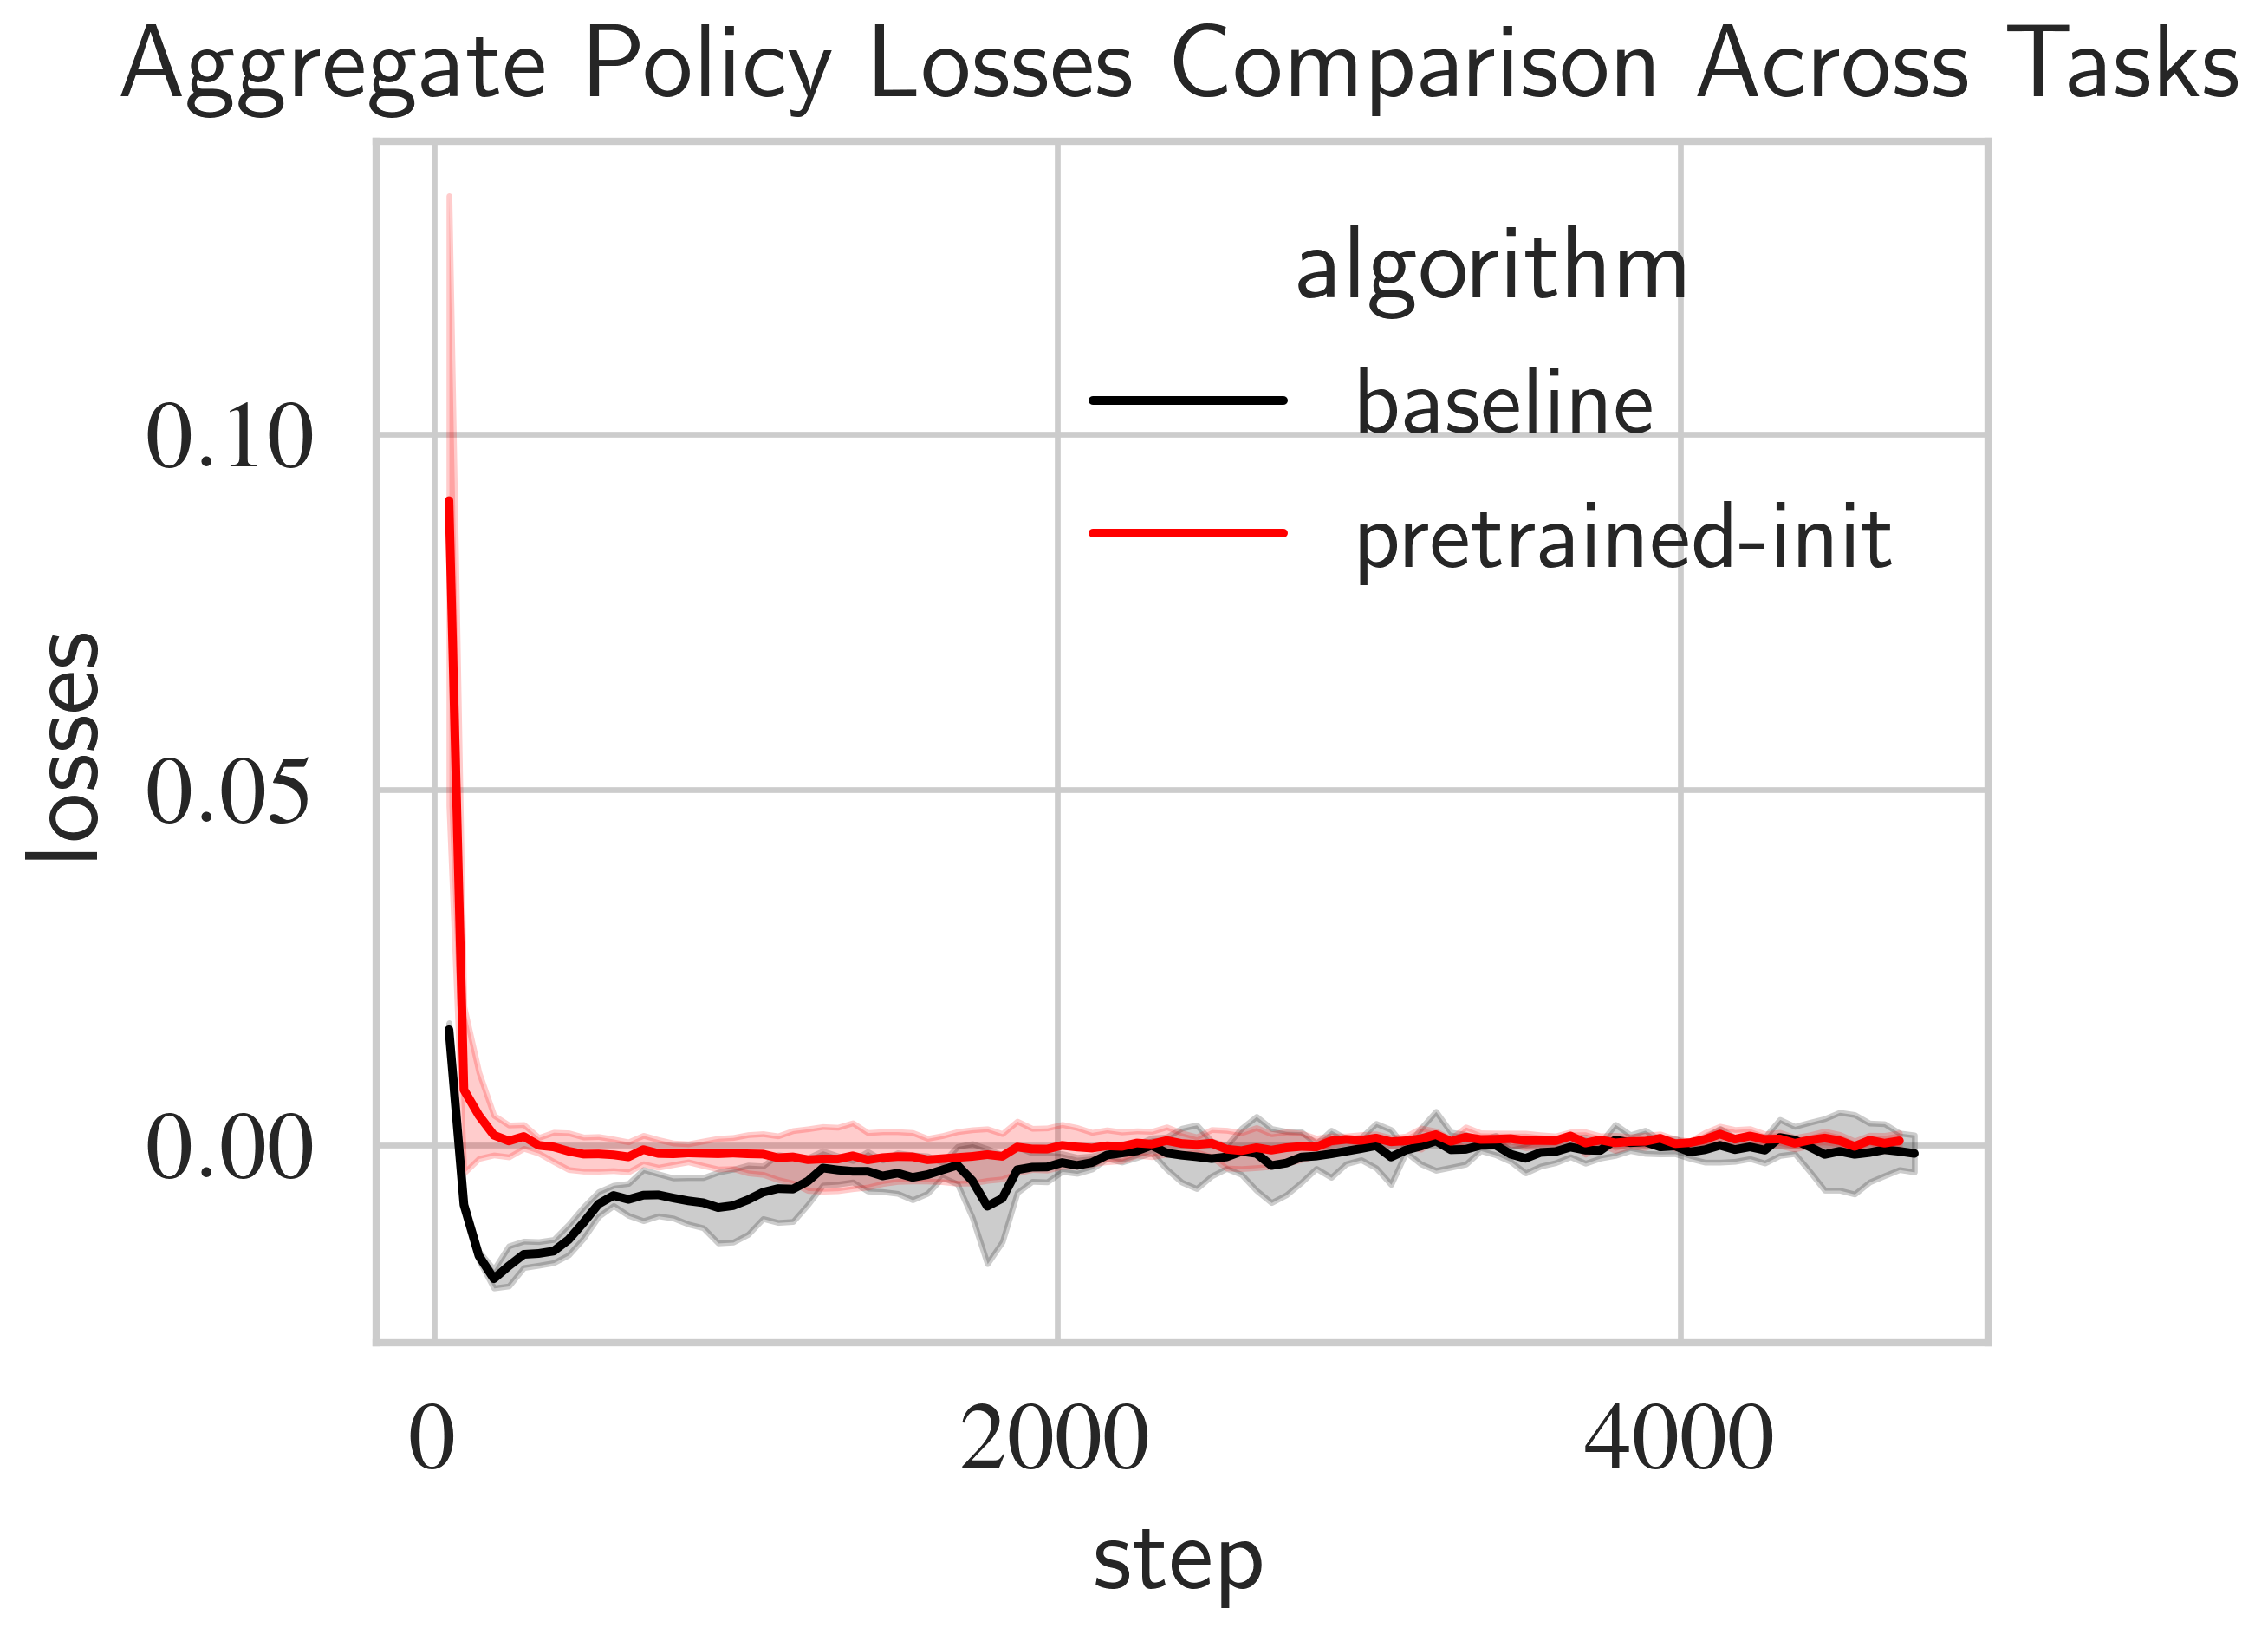

In [ ]:
plt.figure(figsize=(4,3))
ax = sns.lineplot(
    data=loss_summary,
    x="step", y="losses",
    hue="algorithm",
    # style="task",
    errorbar="sd"
)
plt.title("Aggregate Policy Losses Comparison Across Tasks")
# plt.savefig("Policy-losses.pdf", dpi=300)

plt.savefig("Policy-losses.png", dpi=300)